# Project 2 Restaurant Data Analysis

### Project Description
This project analyzes a real-world Restaurant Tipping dataset to uncover consumer spending behavior. It acts as an end-to-end Data Science ETL pipeline using Pandas, NumPy, and Matplotlib.

    day  total_bill       tip    tip_pct
0  Thur   17.682742  2.771452  16.126452
1   Fri   17.151579  2.734737  16.991579
2   Sat   20.441379  2.993103  15.314598
3   Sun   21.410000  3.255132  16.689605


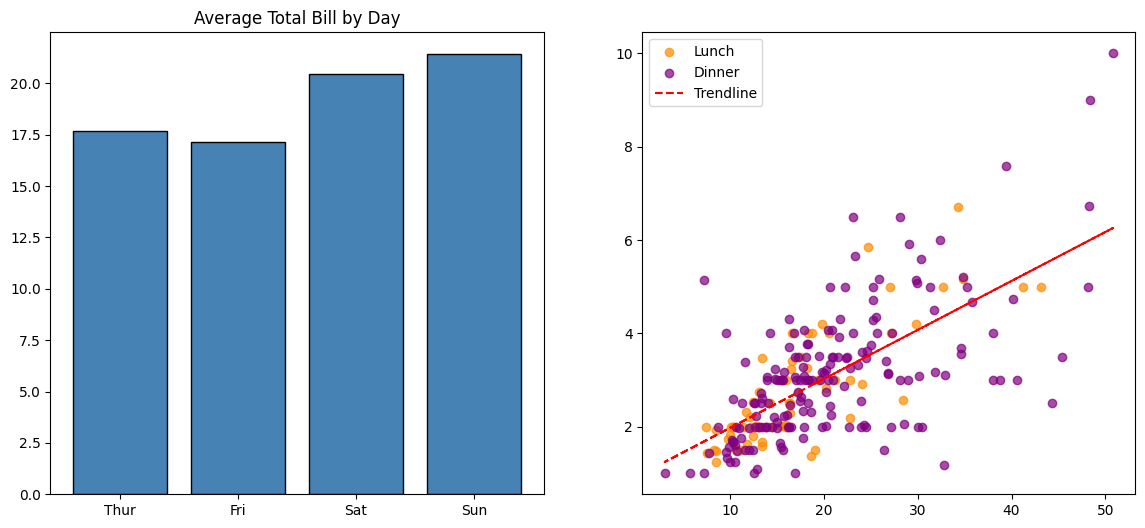

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def analyze_restaurant_data(url: str) -> None:
    df = pd.read_csv(url)
    df['tip_pct'] = np.round((df['tip'] / df['total_bill']) * 100, 2)
    df = df.dropna()
    
    days_order = ['Thur', 'Fri', 'Sat', 'Sun']
    df['day'] = pd.Categorical(df['day'], categories=days_order, ordered=True)
    
    daily_stats = df.groupby('day', observed=True)[['total_bill', 'tip', 'tip_pct']].mean().reset_index()
    print(daily_stats)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    ax1.bar(daily_stats['day'], daily_stats['total_bill'], color='steelblue', edgecolor='black')
    ax1.set_title('Average Total Bill by Day')
    
    lunch_data, dinner_data = df[df['time'] == 'Lunch'], df[df['time'] == 'Dinner']
    ax2.scatter(lunch_data['total_bill'], lunch_data['tip'], color='darkorange', label='Lunch', alpha=0.7)
    ax2.scatter(dinner_data['total_bill'], dinner_data['tip'], color='purple', label='Dinner', alpha=0.7)
    
    z = np.polyfit(df['total_bill'], df['tip'], 1)
    p = np.poly1d(z)
    ax2.plot(df['total_bill'], p(df['total_bill']), "r--", label="Trendline")
    ax2.legend()
    plt.show()

if __name__ == "__main__":
    dataset_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
    analyze_restaurant_data(dataset_url)

### Project Explanation
1. **Extraction:** Loads CSV string directly from GitHub into a Pandas DataFrame.
2. **Transformation:** Engineers a new metric (`tip_pct`) using NumPy vectorized math and orders days categorially.
3. **Aggregation:** Groups by day to find the mathematical mean for bills and tips.
4. **Visualization:** Generates a 1x2 dashboard with a bar chart and scatter plot with a calculated trendline.

### Project Remarks
* **Business Value:** This structure is how Data Analysts generate BI reports.
* **Code Scalability:** Vectorized transformations process millions of rows rapidly.